# Homework #5

## Ensemble learning

This colaboratory contains Homework #5 of the Machine Learning course, which is due **November 19, midnight (23:59 EEST time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.


## Submission's rules:

1.   Please, submit only .ipynb that you extract from the Colaboratory.
2. Run your homework exercises before submitting (output should be present, preferably restart the kernel and press run all the cells).
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.

Please, steer clear of copying someone else's work. If you discuss assignments with anyone in the course, please, mention their names here:

Pooh

##List of Homework's exercises:

1.   [Ex1](#scrollTo=ux5PBYkbwewj) - 2 points
2.   [Ex2](#scrollTo=Z5C3GX9eXFF_) - 4 points
3.   [Ex3](#scrollTo=uHQscVCD7rM0) - 4 points
4.   [Bonus 1](#scrollTo=iJeG56t9-jWI) - 1 point
5.   [Bonus 2](#scrollTo=cLoHOqAcu0Q9) - up to 3 points
6.   [Bonus 3](#scrollTo=jdZkblZW7bEp) - up to 3 points (based on quality of presentation)




---


## Homework exercise 1: implement and train a bagging classifier with 3 K-NN models as estimators (2 points)


<font color='red'> In this exercise you will need to use `classify_knn` function from the first practice session to train three different KNN models on three resamples of this dataset. </font>


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
def create_random_2c_data (D, N):
  """
  Function create_random_2c_data generates two sets of D dimensional
  points (N points each), one for each class. The first set is sampled from D
  dimensional Gaussian distribution with mean 0 and standard deviation 1. The
  second set is generated from the distribution, with mean 1 and standard
  deviation 1.
  """
  # Generating N points for the first class
  mu_vec1 = np.zeros(D) # creates a vector of zeros, these are averages across each dimension
  cov_mat1 = np.eye(D) # creates a diagonal matrix of size D x D, all values except diagonal are 0
  class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, N)

  # The same stuff as above, just averages are shifted into 1
  mu_vec2 = np.ones(D) # creates a vector of ones
  cov_mat2 = np.eye(D)
  class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, N)

  # a lot of boring things....
  # gluing together two matrices generated above
  data = pd.DataFrame(np.concatenate((class1_sample, class2_sample)))

  # Create names for columns
  data.columns = [ 'x' + str(i) for i in (np.arange(D)+1)]

  # Create a class column
  data['class'] = np.concatenate((np.repeat(0, N), np.repeat(1, N)))

  # This is important for plotting and modelling
  data['class'] = data['class'].astype('category')

  return data

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
np.random.seed(2342347823) # random seed, this number was random, no need to build conspiracies around it

D = 2 # two dimensions
N = 100 # points per class

whole_data = create_random_2c_data(D, N)

# Randomly splitting data into train (60%) and validation (40%)
train, val = train_test_split(whole_data, random_state = 111, test_size = 0.40)

n_bootstraps = 3
np.random.seed(1111)

# creating resamples
resamples = [resample(train, n_samples = len(train), replace=True).index.values for i in range(n_bootstraps)]

# first resample
train_resample1 = train.loc[resamples[0]]

# second resample
train_resample2 = train.loc[resamples[1]]

# third resample
train_resample3 = train.loc[resamples[2]]

<font color='red'> Here, I just convert pandas DataFrame into Numpy arrays that are easier to use list comprehension mechanisms on. </font>

In [ ]:
train1 = np.asarray(train_resample1[['x1','x2']])
labels1 = np.asarray(train_resample1[['class']]).reshape((train_resample1.shape[0]))

train2 = np.asarray(train_resample2[['x1','x2']])
labels2 = np.asarray(train_resample2[['class']]).reshape((train_resample2.shape[0]))

train3 = np.asarray(train_resample3[['x1','x2']])
labels3 = np.asarray(train_resample3[['class']]).reshape((train_resample3.shape[0]))

val_points = np.asarray(val[['x1','x2']])
val_labels = np.asarray(val[['class']]).reshape((val.shape[0]))

<font color='red'>  **(Homework exercise 1- a)** Copy and adapt `classify_knn` function from the first homework and practice session to operate on 2D points. **(0.5 points)**</font>

In [ ]:
def dist(point1, point2): # function dist is also from the first practice session
  # sum of squared coordinate-wise differences under sqrt
  return(np.sqrt(np.sum((point2 - point1)**2)))

def classify_knn(val_point, k, train, labels):

  ##### YOUR CODE STARTS #####
  all_distances = [dist(val_point, train_point) for train_point in train]
  knn = np.argsort(all_distances)[0:k]
  counts = [labels[i] for i in knn]
  prediction = np.argmax(np.bincount(counts))
  ##### YOUR CODE ENDS #####

  return prediction

<font color='red'> Test that the function was adapted correctly by running the following example </font>

In [ ]:
val_point = val_points[1]
print(f'predicted class of the first point is {classify_knn(val_point, 5,  train1, labels1)}, while the true class is {val_labels[1]}')

predicted class of the first point is 0, while the true class is 0


<font color='red'> **(Homework exercise 1- b)** Classify each point from the validation set using `classify_knn` function. Use different resamples and list comprehension. Fix `k` at 5. **(1 point)**</font>


In [ ]:
k = 5

# Use three K-NN models that work on three different resamples

##### YOUR CODE STARTS #####
val['knn1'] = [classify_knn(val_point, k, train1, labels1) for val_point in val_points]
val['knn2'] = [classify_knn(val_point, k, train2, labels2) for val_point in val_points]
val['knn3'] = [classify_knn(val_point, k, train3, labels3) for val_point in val_points]

print(f"Accuracy of knn1 {np.sum(val['knn1'] == val['class'])/len(val[['class']])*100}%")
print(f"Accuracy of knn2 {np.sum(val['knn2'] == val['class'])/len(val[['class']])*100}%")
print(f"Accuracy of knn3 {np.sum(val['knn3'] == val['class'])/len(val[['class']])*100}%")
##### YOUR CODE ENDS #####

Accuracy of knn1 67.5%
Accuracy of knn2 68.75%
Accuracy of knn3 63.74999999999999%


<font color='red'> Below aggregate individual predictions using the majority vote approach</font>

In [ ]:
##### YOUR CODE STARTS #####
val['knn_bagging'] = val[['knn1', 'knn2', 'knn3']].mode(axis = 1)
##### YOUR CODE ENDS #####

print(f"Accuracy of hand made bagged ensemble with 3 KNNs is {np.sum(val['knn_bagging'] == val['class'])/len(val[['class']])*100}%")

Accuracy of hand made bagged ensemble with 3 KNNs is 66.25%


<font color='red'> **(Homework exercise 1- c)** Use sklearn `BaggingClassifier` to implement analogous model that uses KNeighborsClassifier as an estimator (with k = 5). Don't forget to use a random state for reproducibility.

Assess its performance on the same validation set and display it. **(0.5 points)**</font>


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier

##### YOUR CODE STARTS #####
np.random.seed(1111)
n_estimators_ = 3
knn_begger = BaggingClassifier(estimator=KNeighborsClassifier(), n_estimators=n_estimators_, max_samples=1.0, bootstrap = True)
knn_begger.fit(train[['x1','x2']], train['class'])
##### YOUR CODE ENDS #####
print(f"Accuracy of sklearn bagging with {3} KNNs {knn_begger.score(val[['x1', 'x2']], val[['class']])*100}%")

Accuracy of sklearn bagging with 3 KNNs 72.5%


## Homework exercise 2: eXtreme Gradient Boosting (XGBoost) (4 points)

<font color='red'> Let's finally build for ourselves a new shiny XGBoost model, the most popular algorithm for Kaggle competitions. </font>
<font color='red'>  Since XGBoost truly shines on tabular data, we are going to use the Thyroid Disease Dataset for training an XGboost model. Further details about this dataset can be found at
 [here](https://www.openml.org/search?type=data&status=active&id=40475). </font>


In [ ]:
from sklearn.datasets import fetch_openml

data = fetch_openml(name="thyroid-allhyper")

/usr/local/lib/python3.10/dist-packages/sklearn/datasets/_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [ ]:
#Let's take a look at data
data.data

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26
0,41.0,1,1,1,1,1,1,1,1,1,...,2,1.30000,2,2.500000,2,125.0,2,1.140000,2,109.000000
1,23.0,1,1,1,1,1,1,1,1,1,...,2,4.10000,2,2.000000,2,102.0,1,0.997912,1,110.787984
2,46.0,2,1,1,1,1,1,1,1,1,...,2,0.98000,1,2.024966,2,109.0,2,0.910000,2,120.000000
3,70.0,1,2,1,1,1,1,1,1,1,...,2,0.16000,2,1.900000,2,175.0,1,0.997912,1,110.787984
4,70.0,1,1,1,1,1,1,1,1,1,...,2,0.72000,2,1.200000,2,61.0,2,0.870000,2,70.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2795,70.0,2,1,1,1,1,1,1,1,1,...,2,2.70000,1,2.024966,2,155.0,2,1.050000,2,148.000000
2796,73.0,2,1,2,1,1,1,1,1,1,...,1,4.67215,2,0.700000,2,63.0,2,0.880000,2,72.000000
2797,75.0,2,1,1,1,1,1,1,1,1,...,1,4.67215,1,2.024966,2,147.0,2,0.800000,2,183.000000
2798,60.0,1,1,1,1,1,1,1,1,1,...,2,1.40000,1,2.024966,2,100.0,2,0.830000,2,121.000000


In [ ]:
# Types of classes
data.target

0       3
1       1
2       1
3       1
4       5
       ..
2795    5
2796    1
2797    1
2798    1
2799    5
Name: Class, Length: 2800, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']

In [ ]:
# Number of instances for each class
data.target.value_counts()

1    1632
5     771
3     275
2      91
4      31
Name: Class, dtype: int64

<font color='red'> **(Homework exercise 2- a)** Complete the preprocessing steps and train the XGBoost model for the Thyroid Disease classification task.
Find additional information regarding the training of an XGBoost model [here](https://xgboost.readthedocs.io/en/latest/python/python_intro.html) **(1.5 points)** </font>

In [ ]:
# Initial data preparation, which involves spliting the dataset into training, validation, and test sets
# Use 80/10/10 datasplit

##### YOUR CODE STARTS #####
from sklearn.model_selection import train_test_split

train_X, test_X, train_y, test_y = train_test_split(data.data, data.target, test_size=0.2, random_state=42)
test_X, val_X, test_y, val_y = train_test_split(test_X, test_y, test_size=0.5, random_state=42)

##### YOUR CODE ENDS #####

NameError: ignored

In [ ]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

##### YOUR CODE STARTS #####

# XGBoost wants data to be wrapped into special formats
dtrain = xgb.DMatrix(train_X, label=train_y, enable_categorical=True)
dval = xgb.DMatrix(val_X, label=val_y, enable_categorical=True)
dtest = xgb.DMatrix(test_X, label=test_y, enable_categorical=True)

# Define the XGBoost parameters (you can add more parameters if you want)
params = {
    "objective": 'multi:softmax',
    "num_class": 6,
    "eval_metric": 'mlogloss',
    "num_boost_round": 20,
    "early_stopping_rounds": 10 # If nothing seems to improve for * * iterations - stop
}

# Train for training and val for validation
evallist = [(dtrain, 'train'), (dval, 'eval')]

# Train the XGBoost model
bst = xgb.train(params=params, dtrain=dtrain, evals=evallist)

##### YOUR CODE ENDS #####

[0]	train-mlogloss:1.35689	eval-mlogloss:1.41587


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [13:53:24] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "early_stopping_rounds", "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


[1]	train-mlogloss:1.13001	eval-mlogloss:1.23656
[2]	train-mlogloss:0.98395	eval-mlogloss:1.12145
[3]	train-mlogloss:0.87931	eval-mlogloss:1.04830
[4]	train-mlogloss:0.79905	eval-mlogloss:0.99497
[5]	train-mlogloss:0.73617	eval-mlogloss:0.95204
[6]	train-mlogloss:0.68529	eval-mlogloss:0.92138
[7]	train-mlogloss:0.64581	eval-mlogloss:0.90322
[8]	train-mlogloss:0.61270	eval-mlogloss:0.88798
[9]	train-mlogloss:0.58770	eval-mlogloss:0.87871


<font color='red'> **(Homework exercise 2- b)**  Make predictions on the test data and evaluate the model **(0.5 points)** </font>

In [ ]:
##### YOUR CODE STARTS #####
ypred = bst.predict(dtest)

acc = accuracy_score(test_y.to_numpy().astype(float), ypred)
print(f"Accuracy: {acc*100}%")

##### YOUR CODE ENDS #####

Accuracy: 70.0%


<font color='red'> **(Homework exercise 2- c)**  In machine learning, feature importance scores are used to determine the relative importance of each feature in a dataset when building a predictive model. Such scores can be derived from a variety of different models, including ensembles. Explore feature importance of the resulting XGBoost model and report the top five most important features **(0.5 points)** </font>



<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

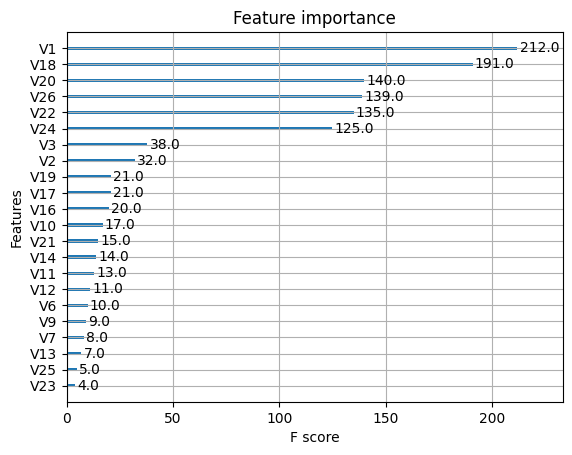

In [ ]:
##### YOUR CODE STARTS #####
xgb.plot_importance(bst)
##### YOUR CODE ENDS #####

<font color='red'> **(Homework exercise 2- d)** Train Adaptive Boosting, Gradient Boosting and a simple KNN model from sklearn (KNeighborsClassifier) on the same training data and evaluate on the same test data. For each model use the default hyperparameters (e.g. `n_estimators` or `n_neighbors`). If you do not want to use default parameters, you can use `cross_val_score` to pick the best values for the hyperparameters using training data. Compare the performance of these three models and XGBoost and draw conclusions in a separate text cell  **(1.5 points)** </font>

In [ ]:
# AdaBoostClassifier
%%time
##### YOUR CODE STARTS #####
from sklearn.ensemble import AdaBoostClassifier
model = AdaBoostClassifier()
model.fit(train_X, train_y)
y_pred = model.predict(test_X)
acc = accuracy_score(test_y.to_numpy().astype(str), y_pred)
print(f"Accuracy: {acc*100}%")
##### YOUR CODE ENDS #####

Accuracy: 46.07142857142857%
CPU times: user 864 ms, sys: 0 ns, total: 864 ms
Wall time: 865 ms


In [ ]:
# GradientBoostingClassifier
%%time
# might take considerable time if trained with default number of n_estimators
##### YOUR CODE STARTS #####
from sklearn.ensemble import GradientBoostingClassifier
gbm = GradientBoostingClassifier()
gbm.fit(train_X, train_y)
y_pred = model.predict(test_X)
acc = accuracy_score(test_y.to_numpy().astype(str), y_pred)
print(f"Accuracy: {acc*100}%")
##### YOUR CODE ENDS #####

Accuracy: 46.07142857142857%
CPU times: user 2.47 s, sys: 0 ns, total: 2.47 s
Wall time: 2.48 s


In [ ]:
# KNeighborsClassifier
%%time
##### YOUR CODE STARTS #####
from sklearn.neighbors import KNeighborsClassifier

model2 = KNeighborsClassifier()
model2.fit(train_X, train_y)
model2_pred = model2.predict(test_X)

acc = accuracy_score(test_y.to_numpy().astype(str), model2_pred)
print(f"Accuracy: {acc*100}%")
##### YOUR CODE ENDS #####

Accuracy: 54.285714285714285%
CPU times: user 90.1 ms, sys: 19.3 ms, total: 109 ms
Wall time: 92.1 ms


<font color='red'> How these models compare with each other and to XGBoost? Can you try to elaborate on this difference? </font>

In [ ]:
# Write your comment here:


Models AdaBoostClassifier, GradientBoostingClassifier and KNeighborsClassifier have lower accurancy in comparison with XGBoost model.

Models were used with default values.

seems like XGBoost is GradientBoostingClassifier on steroids.

## Homework exercise 3: Kaggle in-class to predict COVID-19 mortality (4 points)
<font color='red'> In this exercise we will see how well ensembles work in the real-life problems. Here we are going to work with data from COVID-19 patients, and more specifically we will attempt to predict patient mortality based on clinical information. To this end, we have created a corresponding Kaggle in-class competition: https://www.kaggle.com/t/48a6c8d368b3463faafbce1ec0453afd (this is invitation link). </font>

<font color='red'> **(Homework exercise 3- a)** Getting started: follow the code provided with the Kaggle competition (`sample_notebook.ipynb`) to make the first sample submission using `random_predict` function, Kaggle API or by manually uploading submission file to https://www.kaggle.com/competitions/mlut2023-covid-19-mortality-prediction. Report your score. **(0.5 points)** </font>

In [1]:
import pandas as pd
import numpy as np
import random

<font color='red'> Load `train.csv` and `test.csv` from https://www.kaggle.com/competitions/mlut2023-covid-19-mortality-prediction

In [3]:
from google.colab import files
files.upload();

Saving train.csv to train.csv


In [4]:
files.upload();

Saving test.csv to test.csv


In [5]:
##### YOUR CODE STARTS #####
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
##### YOUR CODE ENDS #####

<font color='red'> Insert your random guesser below:

In [178]:
##### YOUR CODE STARTS #####
def random_predict(test):
    return [random.choice(['recuperado', 'fallecido']) for _ in range(len(test))]

##### YOUR CODE ENDS #####

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


<font color='red'> Create a sample submission below

In [179]:
##### YOUR CODE STARTS #####
sample_submission = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': random_predict(test)})
sample_submission.to_csv('sample_submission.csv', index=False)
##### YOUR CODE ENDS #####

<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()


<font color='red'> You can either use Kaggle API below to submit submission file or download file and submit it manually to Kaggle via web interface. </font>

<font color='red'> You need to have an account on Kaggle.com, before you proceed. When you access your kaggle profile, you need to download your API Token from kaggle. It's very easy:
1. Click on your profile icon
2. Go to **Account**
3. In **API** you press **Create new API token**

<font color='red'> Now we load the file **kaggle.json** that you have downloaded, into this notebook: </font>

In [6]:
files.upload(); # upload your kaggle.json file

Saving kaggle.json to kaggle.json


<font color='red'> The next cell moves the file into a separate folder, sets secure access for it and configures your Kaggle profile for this notebook.</font>

In [7]:
import json

!mkdir /root/.kaggle/
!mv kaggle.json /root/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!kaggle config set -n path -v{/content}

- path is now set to: {/content}


<font color='red'> Assuming that you have accepted the rules of the competition, you should be able to make a submission using the following code: </font>

In [182]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f sample_submission.csv -m "Random guess submission"

<font color='red'> What was the score you received? </font>

In [183]:
# Report your result here:
0.486

0.486

<font color='red'> **(Homework exercise 3- b)** Take off: make two more submissions with at least two different ensemble models we have studied. Make sure to perform all necessary data pre-processing steps to accommodate the requirements of these ensemble models (e.g. data imputation and restructuring). To get full points, shortly summarise your pre-processing, models you have selected and rational behind this choice, and finally report your scores. **(2 points)** </font>

In [ ]:
##### YOUR CODE STARTS #####

# I added code in code blocks see below

##### YOUR CODE ENDS #####

### Preprocessing

In [8]:
!pip install pyjanitor

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 171.8/171.8 kB 2.9 MB/s eta 0:00:00


In [9]:
import janitor
import warnings

def fill_null_with_median(df):
  warnings.filterwarnings("ignore")
  columns_with_null = df.columns[df.isnull().any()]

  df_clean = df.copy()

  # Fill NULL floats with median value
  for column_with_null in columns_with_null:
      if df[column_with_null].dtype == 'float64':
          df_clean = df_clean.fill_empty(column_names=[column_with_null], value=df[column_with_null].median())
  warnings.resetwarnings()
  return df_clean

In [14]:
target_column = 'ESTADO'

train_clean = fill_null_with_median(train)
train_clean = train_clean.drop('FECHA_INGRESO', axis=1)

test_clean = fill_null_with_median(test)
test_clean = test_clean.drop('FECHA_INGRESO', axis=1)

In [15]:
assert train_clean.columns[train_clean.isnull().any()].size == 0, 'Train Dataset has no Null values.'
assert train_clean[train_clean.duplicated()].size == 0, 'Train Dataset should not have duplicated rows'

assert test_clean.columns[test_clean.isnull().any()].size == 0, 'Test Dataset has no Null values.'
assert test_clean[test_clean.duplicated()].size == 0, 'Test Dataset should not have duplicated rows'

### Moadel-1: Adaptive boosting (Adaboost)

In [188]:
from sklearn.model_selection import train_test_split

X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [202]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=4)

scores = np.array([])
model = AdaBoostClassifier()
for train_index, val_index in skf.split(X, y):

  X_train, X_val = X.iloc[train_index], X.iloc[val_index]
  y_train, y_val = y.iloc[train_index], y.iloc[val_index]

  model.fit(X_train, y_train)

  y_pred = model.predict(X_val)

  scores = np.append(scores, model.score(X_val, y_val))

In [203]:
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

0.87 accuracy with a standard deviation of 0.01


In [204]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)
acc = accuracy_score(y_test.to_numpy(), y_pred)
print(f"Accuracy: {(acc*100)}%")

Accuracy: 86.67563930013459%


In [205]:
# Create submission 1st model
test_pred = model.predict(test_clean)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_ada_boost_v1 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_ada_boost_v1.to_csv('submission_ada_boost_v1.csv', index=False)

In [206]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_ada_boost_v1.csv -m "Submission 3-b Model-1 AdaBoost v1"

100% 14.3k/14.3k [00:00<00:00, 17.2kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.70200

### Model-2: Gradient boosting machines (GBM)

In [12]:
estado_encode = {'fallecido': 0, 'recuperado': 1}
estado_decode = {0: 'fallecido', 1: 'recuperado'}

# Apply the mapping to the 'ESTADO' column
train_clean['ESTADO'] = train_clean['ESTADO'].map(estado_encode)

In [219]:
X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

In [220]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier()

scores = np.array([])

for train_index, val_index in skf.split(X, y):

  X_train, X_val = X.iloc[train_index], X.iloc[val_index]
  y_train, y_val = y.iloc[train_index], y.iloc[val_index]

  model.fit(X_train, y_train)

  y_pred = model.predict(X_val)

  scores = np.append(scores, model.score(X_val, y_val))

In [221]:
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

0.87 accuracy with a standard deviation of 0.01


In [222]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test.to_numpy(), y_pred)
print(f"Accuracy: {(acc*100)}%")

Accuracy: 86.67563930013459%


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [230]:
# Create submission 2nd model
test_pred = model.predict(test_clean)
decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_gradient_boost_v1 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_gradient_boost_v1.to_csv('submission_gradient_boost_v1.csv', index=False)

In [231]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_gradient_boost_v1.csv -m "Submission 3-b Model-2 GradientBoost v1"

100% 14.3k/14.3k [00:00<00:00, 17.9kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.71800

In [193]:
##### YOUR CODE STARTS #####

# I added code in code blocks see above

##### YOUR CODE ENDS #####

<font color='red'> Summarise your pre-processing steps, models selected (why these?): </font>

In [194]:
# Add your comment here:


We have a classification problem for a Kaggle competition. I've chosen two models: AdaBoostClassifier and GradientBoostingClassifier.

Both models use ensemble techniques, ideally producing better results than if we were using a single model. According to the scikitlearn documentation, GradientBoosting might be preferred for small sample sizes.

In the pre-processing step, I replaced null values with the median value in the column. Additionally, I dropped the column 'FECHA_INGRESO' with the timestamp.

The column 'ESTADO' is unbalanced, so I made sure to use stratification to split the data and use StratifiedKFold for training. If the prediction results were worse, I would try upsampling or downsampling.

For GradientBoostingClassifier I encoded the target column 'ESTADO' to numeric value, so the model can fit on gradient of the loss function.

<font color='red'> **(Homework exercise 3- c)** Reaching superiority: tune the above models or train a new one (does not have to be ensemble) such that you beat Ms.Smart (`ms_smart.csv`) benchmark. If one or both of your models from 3-b are already superior to Ms.Smart, then you should beat them instead. In order to claim the point in this exercise, describe the model, data pre-processing steps and report your score (which should be higher than Ms Smart's and your previous' models). **(1.5 points)** </font>

In [195]:
##### YOUR CODE STARTS #####

# See code blocks below

##### YOUR CODE ENDS #####

### Submission 1: xgboost

In [270]:
X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test) # make sure to use stratify

In [310]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

dtrain = xgb.DMatrix(X, label=y)
dval = xgb.DMatrix(X_val, label=y_val)
dtest = xgb.DMatrix(X_test, label=y_test)

# Define the XGBoost parameters (you can add more parameters if you want)
params = {
    "num_class": 2,
    "num_boost_round": 20,
}

# Train for training and val for validation
evallist = [(dtrain, 'train'), (dval, 'eval')]

# Train the XGBoost model
bst = xgb.train(params=params, dtrain=dtrain, evals=evallist)

[0]	train-mlogloss:0.51642	eval-mlogloss:0.54793
[1]	train-mlogloss:0.41645	eval-mlogloss:0.46668
[2]	train-mlogloss:0.35104	eval-mlogloss:0.41968
[3]	train-mlogloss:0.30772	eval-mlogloss:0.38794
[4]	train-mlogloss:0.27388	eval-mlogloss:0.36696
[5]	train-mlogloss:0.25016	eval-mlogloss:0.35149


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [19:18:29] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


[6]	train-mlogloss:0.23087	eval-mlogloss:0.33469
[7]	train-mlogloss:0.21661	eval-mlogloss:0.32512
[8]	train-mlogloss:0.20174	eval-mlogloss:0.32067
[9]	train-mlogloss:0.18431	eval-mlogloss:0.31777


In [291]:
test_pred = bst.predict(dtest)

acc = accuracy_score(y_test.to_numpy(), test_pred)
print(f"Accuracy: {acc*100}%")

Accuracy: 86.52291105121293%


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

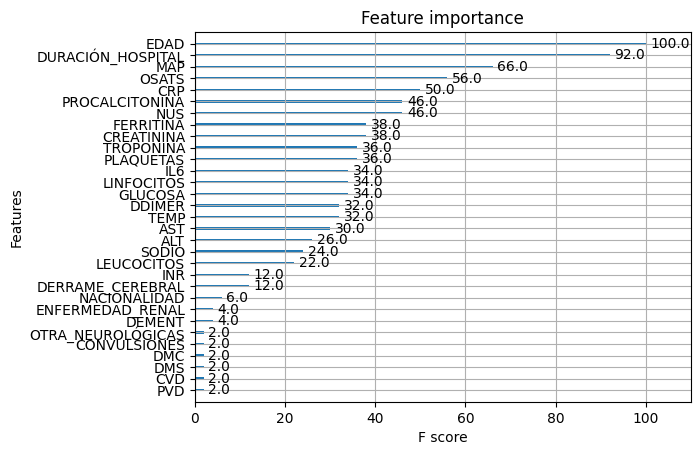

In [273]:
xgb.plot_importance(bst)

In [288]:
# Create submission 2nd model
test_pred = bst.predict(xgb.DMatrix(test_clean))

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_xgb_v2 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_xgb_v2.to_csv('submission_xgb_v2.csv', index=False) # v1 has a bug

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [289]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_xgb_v2.csv -m "Submission 3-c XGBoost v2"

100% 14.3k/14.3k [00:00<00:00, 18.8kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.698

### Submission 2: xgboost

In [338]:
X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [339]:
dtrain = xgb.DMatrix(X, label=y)
dtest = xgb.DMatrix(X_test, label=y_test)

# Define the XGBoost parameters (you can add more parameters if you want)
params = {
    "num_class": 2,
    "num_boost_round": 100,  # Adjust based on performance
    "max_depth": 3,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "alpha": 0.2,  # L1
    "lambda": 0.2,  # L2
}

xgb.cv(
    params=params, dtrain=dtrain,
    nfold=5,
    metrics='merror',
)


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [19:37:56] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


,train-merror-mean,train-merror-std,test-merror-mean,test-merror-std
0,0.129464,0.003532,0.139820,0.013125
1,0.126768,0.003852,0.138474,0.012488
2,0.124831,0.001881,0.137796,0.017555
3,0.124242,0.002536,0.137125,0.015042
4,0.123568,0.003095,0.138472,0.015289
5,0.122051,0.003043,0.137125,0.015670
6,0.120788,0.003364,0.135104,0.017832
7,0.120114,0.003589,0.133420,0.018825
8,0.120451,0.002840,0.134431,0.018371
9,0.119777,0.003167,0.133420,0.017056


In [340]:
test_pred = bst.predict(dtest)

acc = accuracy_score(y_test.to_numpy(), test_pred)
print(f"Accuracy: {acc*100}%")

Accuracy: 87.61776581426649%


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

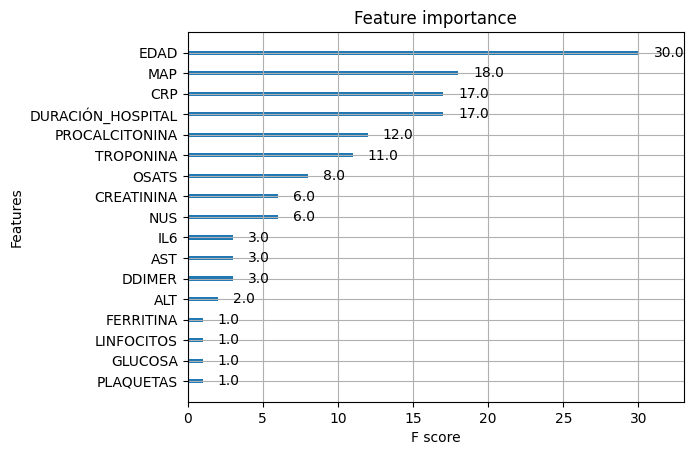

In [342]:
xgb.plot_importance(bst)

In [343]:
test_pred = bst.predict(xgb.DMatrix(test_clean))

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_xgb_v3 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_xgb_v3.to_csv('submission_xgb_v3.csv', index=False)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [344]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_xgb_v3.csv -m "Submission 3-c XGBoost v3"

100% 14.4k/14.4k [00:00<00:00, 16.5kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.672

### Submission 3: StackingClassifier

In [347]:
X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

In [349]:
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

estimators = [
    ('decision_tree', DecisionTreeClassifier()),
    ('knn', KNeighborsClassifier()),
    ('log_reg', LogisticRegression()),
    ('g_boost', GradientBoostingClassifier())
]

n_folds = 4

stacking_classifier = StackingClassifier(estimators=estimators, final_estimator=SVC(), cv=n_folds)
stacking_classifier.fit(X, y)
print(f"Accuracy of sklearn stacking ensemble {stacking_classifier.score(X_test, y_test)*100}%")

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Accuracy of sklearn stacking ensemble 86.54104979811575%


In [350]:
test_pred = stacking_classifier.predict(test_clean)

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_stacking_v4 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_stacking_v4.to_csv('submission_stacking_v4.csv', index=False)

In [351]:
#!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_stacking_v4.csv -m "Submission 3-c stacking v4"

100% 14.3k/14.3k [00:01<00:00, 13.1kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

### Submission 4: *xgboost*

In [17]:
from sklearn.model_selection import train_test_split

X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen 

In [19]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

dtrain = xgb.DMatrix(X, label=y)
dtest = xgb.DMatrix(X_test, label=y_test)

# Define the XGBoost parameters (you can add more parameters if you want)
params = {
    "num_class": 2,
    "num_boost_round": 100,  # Adjust based on performance
    "max_depth": 3,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "alpha": 0.2,  # L1
    "lambda": 0.2,  # L2
}

cv_results = xgb.cv(
    params=params, dtrain=dtrain,
    nfold=4,
    metrics='merror',
)

# Determine the optimal number of boosting rounds based on cross-validated results
optimal_rounds = cv_results.shape[0]


# Train the final model with the determined number of boosting rounds
bst = xgb.train(params=params, dtrain=dtrain, num_boost_round=optimal_rounds)

<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()
/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [20:58:23] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.10/dist-packages/xgboost/core

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()


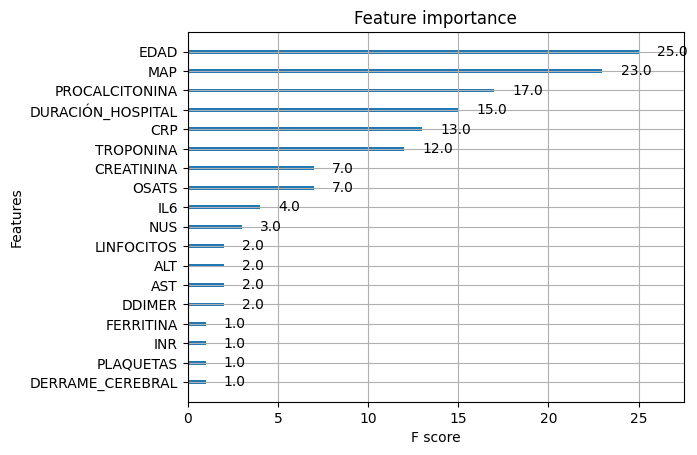

In [20]:
xgb.plot_importance(bst)

In [21]:
test_pred = bst.predict(dtest)

acc = accuracy_score(y_test.to_numpy(), test_pred)
print(f"Accuracy: {acc*100}%")

Accuracy: 86.27187079407807%


In [440]:
test_pred = bst.predict(xgb.DMatrix(test_clean))

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_xgb_v5 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_xgb_v5.to_csv('submission_xgb_v5.csv', index=False)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [441]:
!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_xgb_v5.csv -m "Submission 3-c XGBoost v5"

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


100% 14.4k/14.4k [00:00<00:00, 18.9kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

In [22]:
# Drop less important features

feature_importance = bst.get_fscore()
feature_importance_df = pd.DataFrame(list(feature_importance.items()), columns=['Feature', 'Importance'])
feature_importance_df = feature_importance_df.sort_values('Importance', ascending=False)
threshold = 5

important_features = feature_importance_df[feature_importance_df['Importance'] < threshold]['Feature']

test_clean = test_clean[important_features]

important_features = [target_column] + list(important_features)

train_clean = train_clean[important_features]

In [23]:
X = train_clean.drop(target_column, axis=1)
y = train_clean[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y) # make sure to use stratify

In [24]:
dtrain = xgb.DMatrix(X, label=y)
dtest = xgb.DMatrix(X_test, label=y_test)

# Define the XGBoost parameters (you can add more parameters if you want)
params = {
    "num_class": 2,
    "num_boost_round": 100,  # Adjust based on performance
    "max_depth": 3,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "alpha": 0.2,  # L1
    "lambda": 0.2,  # L2
}

cv_results = xgb.cv(
    params=params, dtrain=dtrain,
    nfold=4,
    metrics='merror',
)

# Determine the optimal number of boosting rounds based on cross-validated results
optimal_rounds = cv_results.shape[0]

# Train the final model with the determined number of boosting rounds
bst = xgb.train(params=params, dtrain=dtrain, num_boost_round=optimal_rounds)


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [20:59:22] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [20:59:22] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

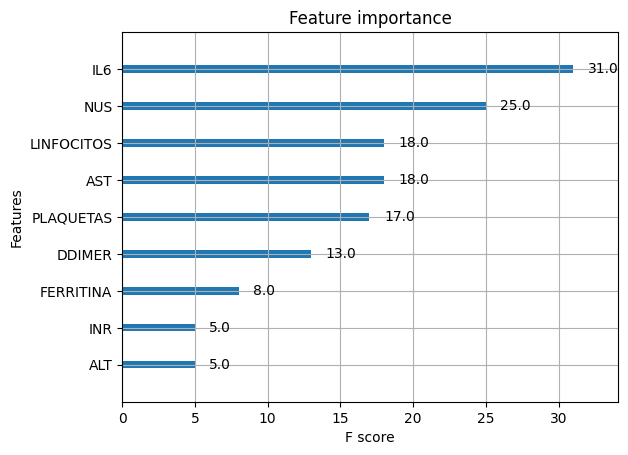

In [25]:
xgb.plot_importance(bst)

In [26]:
test_pred = bst.predict(dtest)

acc = accuracy_score(y_test.to_numpy(), test_pred)
print(f"Accuracy: {acc*100}%")

Accuracy: 82.36877523553163%


In [27]:
test_pred = bst.predict(xgb.DMatrix(test_clean))

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_xgb_v6 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_xgb_v6.to_csv('submission_xgb_v6.csv', index=False)

<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()


In [28]:
!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_xgb_v6.csv -m "Submission 3-c XGBoost drop features v6"

100% 14.5k/14.5k [00:02<00:00, 7.24kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.56

### Submission 5: *xgboost*

In [123]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train = train.drop('FECHA_INGRESO', axis=1)
test = test.drop('FECHA_INGRESO', axis=1)
train['ESTADO'] = train['ESTADO'].map(estado_encode)

X = train.drop(target_column, axis=1)
y = train[target_column]
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [124]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

dtrain = xgb.DMatrix(X, label=y)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "max_depth": 5,
    "learning_rate": 0.2,
    "subsample": 0.2,
    "colsample_bytree": 0.8,
    # 'colsample_bytree':0.8, 'colsample_bylevel':0.8, 'colsample_bynode':0.8,
    "num_boost_round": 100,
    "alpha": 3,  # L1
    "lambda": 0.5,  # L2
}

optimal_rounds = xgb.cv(
    params=params,
    dtrain=dtrain,
    nfold=4,
    metrics="logloss",
    early_stopping_rounds=10,
)

print(optimal_rounds)

optimal_rounds = cv_results.shape[0]

bst = xgb.train(params=params, dtrain=dtrain, num_boost_round=optimal_rounds)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [21:53:03] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [21:53:04] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


   train-logloss-mean  train-logloss-std  test-logloss-mean  test-logloss-std
0            0.426317           0.006076           0.428628          0.020751
1            0.400661           0.006620           0.408575          0.021977
2            0.377039           0.004746           0.387133          0.017590
3            0.361612           0.003711           0.375299          0.014877
4            0.348809           0.003693           0.364769          0.015280
5            0.338485           0.003967           0.358774          0.015247
6            0.327409           0.003418           0.351495          0.016876
7            0.317586           0.001949           0.343789          0.018056
8            0.309775           0.001730           0.337798          0.018759
9            0.302602           0.001291           0.333094          0.018293


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:160: UserWarning: [21:53:07] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "num_boost_round" } are not used.

  warnings.warn(smsg, UserWarning)


In [115]:
test_pred = bst.predict(dtest)
test_pred = [1 if pred > 0.5 else 0 for pred in test_pred]
acc = accuracy_score(y_test.to_numpy(), test_pred)
print(f"Accuracy: {acc*100}%")

Accuracy: 86.13728129205921%


In [118]:
test_pred = bst.predict(xgb.DMatrix(test))
test_pred = [1 if pred > 0.5 else 0 for pred in test_pred]

decoder = np.vectorize(lambda x: estado_decode[x])
test_pred = decoder(test_pred)

assert test_pred.size == test_clean.shape[0]
assert test_pred.size == test.shape[0]

submission_xgb_v7 = pd.DataFrame({'ID': list(range(0, len(test))), 'ESTADO': test_pred})
submission_xgb_v7.to_csv('submission_xgb_v7.csv', index=False)

In [119]:
!kaggle competitions submit -c mlut2023-covid-19-mortality-prediction -f submission_xgb_v7.csv -m "Submission 3-c XGBoost drop features v7"

100% 14.4k/14.4k [00:02<00:00, 5.63kB/s]
Successfully submitted to ML@UT2023 COVID-19 Mortality Prediction

Score: 0.68

In [ ]:
##### YOUR CODE STARTS #####

# See code blocks above

##### YOUR CODE ENDS #####

<font color='red'> Summarise your pre-processing steps, models selected (why these?), and the "special sauce" (what you changed compared to 3-b) below: </font>

In [196]:
# Add your comment here:


My understanding that XGBoost is well written and configured model, which is easy to get good results. I was under impression that XGBoost will beat AdaBoost and GradientBoost.

I initially kept data preprocessed in the same way as for previous models. But XGBoost showed signs of overfitting, results on training data was lower.

I tried to drop some unimportant features, but it showed quite bad results ~0.56

In the end I decided to skip preprocessing because XGBoost can handle nulls. But I results was lower then for GradientBoosting.



# Bonus exercises
*(NB, these are optional exercises!)*


##Bonus exercise 1 (1 bonus point): Interim Champion

<font color='red'> If at any point of time your submission lended at the top of the **public leaderboard** from the Kaggle competition (Exercise 3), take a screenshot of this remarkable achievement before it is too late and somebody else did not knock it off. Post this screenshot below (add a picture). Describe your solution below (do not have to write too much, just the main idea). You can only get this point once.

In [197]:
# Add your comment here:


##Bonus exercise 2 (up to 3 bonus points): Top Perfomer Challenge

<font color='red'> You are encouraged to compete for the top three places in the Kaggle competition described in Exercise 3. So, **3 points** for the first place, **2 points** for the second place and **1.5 points** for the third place.

<font color='red'> To receive the bonus points, you must finish in the top three of the **private leaderboard** and maintain your position throughout the competition. The end of the competition is 19.11.2023 23:59:59.</font>

## Bonus exercise 3 (up to 3 bonus points depending on presentation): Discrete AdaBoost from scratch



<font color='red'> In the class we have discussed a simplified version of the AdaBoost, the goal of this task is to implement an unabrdiged version of the Discrete AdaBoost classifier following the instructions from the paper [Friedman et al (2000)](https://hastie.su.domains/Papers/AdditiveLogisticRegression/alr.pdf). In a nutshell, AdaBoost classifier assigns initial weights to training examples, fits a weak classifier, and updates the data and classifier weights based on classification accuracy. The process is repeated for each weak estimator. The final strong classifier combines weak classifiers with different weights.</font>

<font color='red'> Implement AdaBoost classifier.

Tips:

- use `DecisionTreeClassifier` from `sklearn` as a weak classifier
- avoid division by zero
- pay attention to the format of data labels.</font>



In [198]:
class AdaBoost:
  def __init__(self, n_estimators=50):
    self.n_estimators = n_estimators
    self.estimator_weights = []
    self.models = []

  def fit(self, X, y):
    ##### YOUR CODE STARTS #####
    ...
    ##### YOUR CODE ENDS #####

  def predict(self, X):
    ##### YOUR CODE STARTS #####
    ...
    ##### YOUR CODE ENDS #####



<font color='red'> Test your model on the dataset from exercise 3. Report accuracy on the test set and observe how the performance changes with the different number of estimators.</font>

In [199]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Use sklearn implementation of AdaBoost classifier with the same parameters as you used for your implementation. Report accuracy on the test set as well. </font>

In [200]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Report difference in results, if there are any. Explain why sklearn's model behaves differently, you might want to take a look at sklearn's [code](https://github.com/scikit-learn/scikit-learn/blob/093e0cf14/sklearn/ensemble/_weight_boosting.py#L341) :)</font>

<font color='red'> Your answer:</font>

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the practice session, possibly answering the following questions:

* how much time did you spend on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us

In [201]:
# Add your comments here:
